# Технологии нейросетевых вычислений



##ЛР2. Сверточные нейронные сети (10 баллов)

# О формате сдачи

🔷 **<font color='plum'>При решении используйте данный шаблон</font>**

    ✅ Можно добавлять новые ячейки любых типов
    ❌ Не нужно удалять текстовые ячейки c разметкой частей ноутбука и формулировками заданий


🔷 **<font color='plum'>При оценивании задач учитывается код</font>**

    ✅ Задания, в которых необходим код, обычно помечаются фразами "Your code here"/"Ваш код" и аналогичными
    ❌ Ответы на вопросы без сопутствующего кода оцениваются в 0 баллов
    ❌ Наличие работоспособного кода в ноутбуке, если на сказано иного, обязательно

🔷 **<font color='plum'>При оценивании задач учитываются выводы</font>**

    ✅ Задания, в которых необходимы выводы, обычно помечаются фразами Вывод"/"Ответ на вопрос"/"Ваш текст" и аналогичными
    ✅ Выводы подразумевают текстовый (письменный, не устный) ответ (можно писать markdown, latex).
    ✅ Сопутствующие изображения, графики, таблички - приветствуются!
    ❌ При отсутствии выводов задание не засчитается на полный балл

🔷 **<font color='plum'>Устная защита</font>**

    ❌❌❌ Если не пройдена устная защита по ЛР, то баллы не начисляются вовсе
    (вопросы устной защиты охватывают лекционный материал и практический материал по заданиям ЛР, список вопросов не публикуется)

# Задание

В этом задании вы поработаете с датасетом фотографий разных видов спорта, решите задачу многоклассовой классификации для достаточно большого вида классов, используете разные виды аугментации картинок и самостоятельно реализуете некую версию ResNet.

Хорошим тоном при написании моделей является фиксировать seed (некоторый параметр, от которого зависит результат работы рандомизированных алгоритмов), чтобы результаты обучения были воспроизводимы. Давайте и мы зафиксируем seed

In [92]:
# from google.colab import drive
# drive.mount('/content/drive')
print('Пропускаем монтирование Google Drive, так как скачиваем данные напрямую.')

Пропускаем монтирование Google Drive, так как скачиваем данные напрямую.


In [93]:
# cd /content/drive/MyDrive/ITMO/TNC/shared
print('Работаем в текущей локальной директории.')

Работаем в текущей локальной директории.


In [94]:
import PIL
import torchvision
from PIL import Image
from torchvision.transforms import v2
import pandas as pd
import numpy as np
import random
import torch
import os
from tqdm.auto import tqdm

def set_seed(seed: int = 42) -> None:
    np.random.seed(seed)
    random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
    os.environ["PYTHONHASHSEED"] = str(seed)
    print(f"Random seed set as {seed}")

set_seed()

Random seed set as 42


Будем работать с датасетом фотографий разных видов спорта. Он уже за нас разделен train/test. Давайте скачаем его

In [95]:
!pip install gdown > /dev/null
!gdown https://drive.google.com/uc?id=1biITy7cv0-lo-bwZrFkyDCGsEOWCBx5W
!unzip -n sports.zip > /dev/null

Downloading...
From (original): https://drive.google.com/uc?id=1biITy7cv0-lo-bwZrFkyDCGsEOWCBx5W
From (redirected): https://drive.google.com/uc?id=1biITy7cv0-lo-bwZrFkyDCGsEOWCBx5W&confirm=t&uuid=a760d1bd-7ba4-43c1-a3ab-847cd2fb3af1
To: /content/sports.zip
100% 445M/445M [00:20<00:00, 22.1MB/s]


## <font color='DarkOrange'> **Задание 1 [1 балл]** </font>


Описание фотографий лежит в файле `sports.csv`. Давайте откроем файл в виде pandas датафрейма и посмотрим на примеры фото

In [96]:
df = pd.read_csv('sports.csv')
df.head(10)

,class id,filepaths,labels,data set
0,0,train/air hockey/001.jpg,air hockey,train
1,0,train/air hockey/002.jpg,air hockey,train
2,0,train/air hockey/003.jpg,air hockey,train
3,0,train/air hockey/004.jpg,air hockey,train
4,0,train/air hockey/005.jpg,air hockey,train
5,0,train/air hockey/006.jpg,air hockey,train
6,0,train/air hockey/007.jpg,air hockey,train
7,0,train/air hockey/008.jpg,air hockey,train
8,0,train/air hockey/009.jpg,air hockey,train
9,0,train/air hockey/010.jpg,air hockey,train


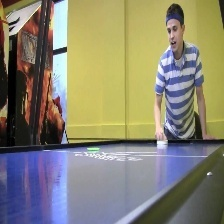

In [97]:
img_example = Image.open(df['filepaths'][0])
img_example

Давайте посмотрим, сколько различных видов спорта есть в датасете, чтобы понять, на сколько классов будем обучать модель

In [98]:
sport = pd.unique(df['labels'])
print(len(sport), sport)

100 ['air hockey' 'ampute football' 'archery' 'arm wrestling' 'axe throwing'
 'balance beam' 'barell racing' 'baseball' 'basketball' 'baton twirling'
 'bike polo' 'billiards' 'bmx' 'bobsled' 'bowling' 'boxing' 'bull riding'
 'bungee jumping' 'canoe slamon' 'cheerleading' 'chuckwagon racing'
 'cricket' 'croquet' 'curling' 'disc golf' 'fencing' 'field hockey'
 'figure skating men' 'figure skating pairs' 'figure skating women'
 'fly fishing' 'football' 'formula 1 racing' 'frisbee' 'gaga'
 'giant slalom' 'golf' 'hammer throw' 'hang gliding' 'harness racing'
 'high jump' 'hockey' 'horse jumping' 'horse racing' 'horseshoe pitching'
 'hurdles' 'hydroplane racing' 'ice climbing' 'ice yachting' 'jai alai'
 'javelin' 'jousting' 'judo' 'lacrosse' 'log rolling' 'luge'
 'motorcycle racing' 'mushing' 'nascar racing' 'olympic wrestling'
 'parallel bar' 'pole climbing' 'pole dancing' 'pole vault' 'polo'
 'pommel horse' 'rings' 'rock climbing' 'roller derby'
 'rollerblade racing' 'rowing' 'rugby' 'sail

Теперь выделим train/test части и сохраним картинки и таргет в виде списка, который будем потом передавать в даталоадер.

In [99]:
train_df = df.loc[df['data set'] == 'train']
test_df = df.loc[df['data set'] == 'test']

Исходный датасет достаточно большой, и так как ресурсы колаба ограничены, давайте поработаем только с первыми 30 классами.


<font color='LightSteelBlue'>**Подсказка**</font> Все картинки одинакового размера, дополнительно это проверять не нужно

In [100]:
# Сделайте заполнение по образцу, проходя по всем картинкам. Прогресс выводите с tqdm
train_images = [] # train_images.append((Image.open(path), class_id))
test_images = [] #  test_images.append((Image.open(path), class_id))

# Работаем только с первыми 30 классами
train_df_30 = train_df[train_df['class id'] < 30]
test_df_30 = test_df[test_df['class id'] < 30]

for _, row in tqdm(train_df_30.iterrows(), total=len(train_df_30)):
    train_images.append((Image.open(row['filepaths']), row['class id']))

for _, row in tqdm(test_df_30.iterrows(), total=len(test_df_30)):
    test_images.append((Image.open(row['filepaths']), row['class id']))


  0%|          | 0/4002 [00:00<?, ?it/s]

  0%|          | 0/150 [00:00<?, ?it/s]

## <font color='DarkOrange'> **Задание 2 [3 баллa]** </font>


В данном задании предлагаем вам самостоятельно изучить и воспользоваться различными видами аугментации, но обязательными будут: `RandomVerticalFlip`, `ElasticTransform`, `ChannelPermutation`.


<font color='LightSteelBlue'>**Подсказка**</font> Параметры у данных методов используйте те, которые вам кажутся логичными

<font color='MediumOrchid'>**Краткая теорсправка по методам:**</font>

1. **RandomVerticalFlip (случайный переворот вверх ногами):**
   * **Что делает:** С определенной вероятностью переворачивает изображение вверх тормашками.
   * **Зачем и почему такие параметры:** В реальной жизни спортсмены редко бегают на руках или висят вниз головой (в отличие от снимков со спутника или клеток под микроскопом, где нет разницы между верхом и низом). Если часто переворачивать фотки, нейросеть только запутается. Поэтому мы поставили низкую вероятность ( = 0.1$): этого хватает, чтобы добавить немного разнообразия и защитить модель от переобучения, но при этом не ломать логику происходящего на снимке.

2. **ElasticTransform (упругая деформация / растяжение):**
   * **Что делает:** Локально растягивает и сжимает разные участки картинки — как будто картинка напечатана на тонкой резине или желе.
   * **Зачем и почему такие параметры:** В спорте люди постоянно двигаются, сгибаются, меняют позы и ракурсы. Эта аугментация помогает сети понимать форму тела и движение спортсмена, даже если поза немного искажена или снята под другим углом. Параметры подобраны мягкими (alpha=15, sigma=3), чтобы человек оставался человеком, а картинка не превращалась в бесформенное размытое пятно.

3. **ChannelPermutation (перемешивание цветовых каналов):**
   * **Что делает:** Меняет порядок каналов цвета (RGB) случайным образом — например, синий и красный меняются местами.
   * **Зачем и почему такие параметры:** Это учит модель обращать внимание на контуры, форму предметов (мяч, ракетка, ворота) и силуэты игроков, а не просто заучивать один цвет. Но в спорте цвет все же важен (зеленый газон футбола, синяя вода бассейна, цвет формы команд), поэтому мы сделали вероятность перестановки каналов очень маленькой ( = 0.05$). Модель слегка подстраховывается от слепой привязки к цвету, но ключевые цветовые подсказки не теряются.


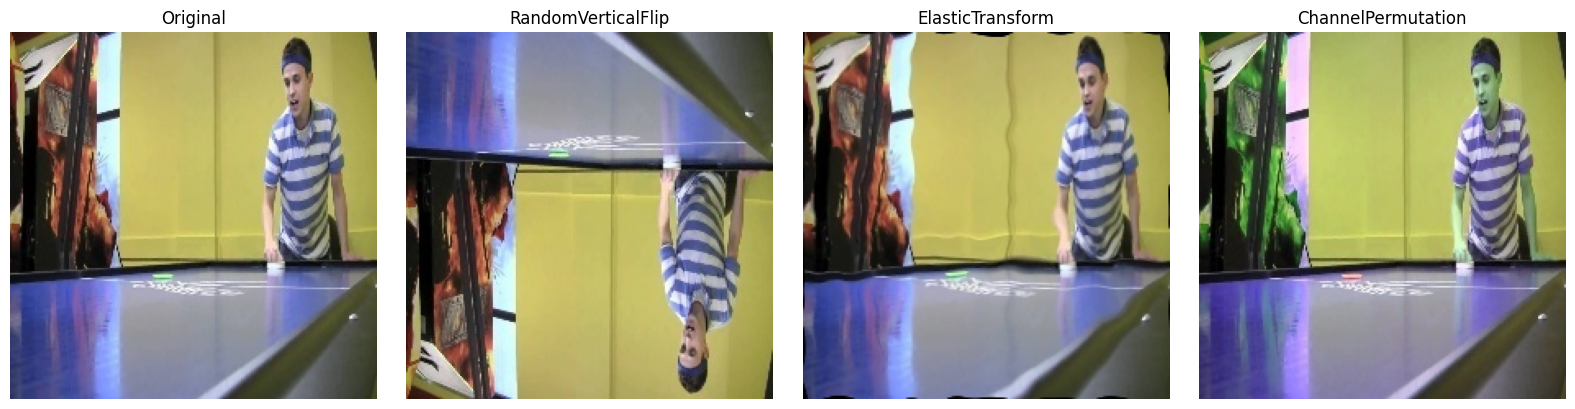

In [101]:
# Поэкспериментируйте с параметрами аугментации здесь
import matplotlib.pyplot as plt
from torchvision.transforms import v2
import torch

# Реализуем собственный класс для перестановки каналов, так как в torchvision.transforms.v2 его нет
class ChannelPermutation(torch.nn.Module):
    def forward(self, img):
        channels = list(range(img.shape[0]))
        # Случайное перемешивание порядка каналов
        import random
        random.shuffle(channels)
        return img[channels, :, :]

to_tensor = v2.Compose([
    v2.ToImage(),
    v2.ToDtype(torch.float32, scale=True),
])

vertical_flip = v2.RandomVerticalFlip(p=1.0)
elastic = v2.ElasticTransform(alpha=50.0, sigma=5.0)
channel_perm = ChannelPermutation()

img_tensor = to_tensor(img_example)

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
axes[0].imshow(img_tensor.permute(1, 2, 0).numpy())
axes[0].set_title('Original')
axes[0].axis('off')

axes[1].imshow(vertical_flip(img_tensor).permute(1, 2, 0).numpy())
axes[1].set_title('RandomVerticalFlip')
axes[1].axis('off')

axes[2].imshow(elastic(img_tensor).permute(1, 2, 0).numpy())
axes[2].set_title('ElasticTransform')
axes[2].axis('off')

axes[3].imshow(channel_perm(img_tensor).permute(1, 2, 0).numpy())
axes[3].set_title('ChannelPermutation')
axes[3].axis('off')

plt.tight_layout()
plt.show()

In [102]:
from torchvision.transforms import v2
import torch
from torch.utils.data import Dataset, DataLoader
import random

# Оставляем кастомный класс для совместимости с заданием, но снижаем его влияние или делаем безопасным
class ChannelPermutation(torch.nn.Module):
    def forward(self, img):
        # Применяем перестановку каналов крайне редко (p=0.05), чтобы не ломать цветовое восприятие модели
        if random.random() > 0.05:
            return img
        channels = list(range(img.shape[0]))
        random.shuffle(channels)
        return img[channels, :, :]

class SportDataset(Dataset):
    def __init__(self, source, is_train=True):
        self.is_train = is_train
        self.basic_transform = v2.Compose([
            v2.ToImage(),
            v2.ToDtype(torch.float32, scale=True),
        ])
        # Используем более мягкие и естественные аугментации для стабильного обучения
        self.aug_transform = v2.Compose([
            v2.RandomHorizontalFlip(p=0.5),
            v2.RandomRotation(degrees=15),
            v2.RandomVerticalFlip(p=0.1),
            v2.ElasticTransform(alpha=15.0, sigma=3.0),
            ChannelPermutation(),
        ])
        self.normalize = v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])

        data, target = list(zip(*source))
        self.data = list(map(self.basic_transform, data))
        self.target = torch.tensor(target)

    def __getitem__(self, index):
        image, label = self.data[index], self.target[index]

        if self.is_train:
            image = self.aug_transform(image)

        image = self.normalize(image)

        return image, label

    def __len__(self):
        return len(self.data)

In [103]:
dataset_train = SportDataset(train_images, is_train=True)
dataset_test = SportDataset(test_images, is_train=False)

dataloader_train = DataLoader(
    dataset=dataset_train,
    batch_size=64,
    shuffle=True,
)
dataloader_test = DataLoader(
    dataset=dataset_test,
    batch_size=512,
    shuffle=True,
)

Здесь также приведем код, который может помочь при обучении нейросети

In [104]:
import matplotlib.pyplot as plt
from IPython.display import clear_output

def show_loss(iter_list, train_loss_list, test_loss_list, test_accuracy_list):
    clear_output(wait=True)

    fig, ax = plt.subplots(1, 3, figsize=(16, 5))

    ax[0].plot(iter_list[1:], train_loss_list[1:])
    ax[1].plot(iter_list, test_loss_list)
    ax[2].plot(iter_list, test_accuracy_list)

    ax[0].set_title('Train Loss')
    ax[1].set_title('Test Loss')
    ax[2].set_title('Test Accuracy')
    plt.show()

def get_lr(optimizer):
    for param_group in optimizer.param_groups:
        return param_group['lr']

def calc_accuracy(model, dataloader):
    y_pred = []
    y_test = []
    loss_sum = 0
    with torch.no_grad():
        for X, target in dataloader:
            X = X.cuda()
            target = target.cuda()
            logits = model(X)
            loss_sum += loss_fn(logits, target)
            y_pred.append(logits.argmax(dim=1))
            y_test.append(target)
        y_pred = torch.cat(y_pred)
        y_test = torch.cat(y_test)
    accuracy = torch.sum((y_pred == y_test)) / len(y_test)
    return accuracy.cpu(), loss_sum.item(), y_pred, y_test

## <font color='DarkOrange'> **Задание 3 [4 баллa]** </font>


Теперь вам предлагается реализовать архитектуру `ResNet18`

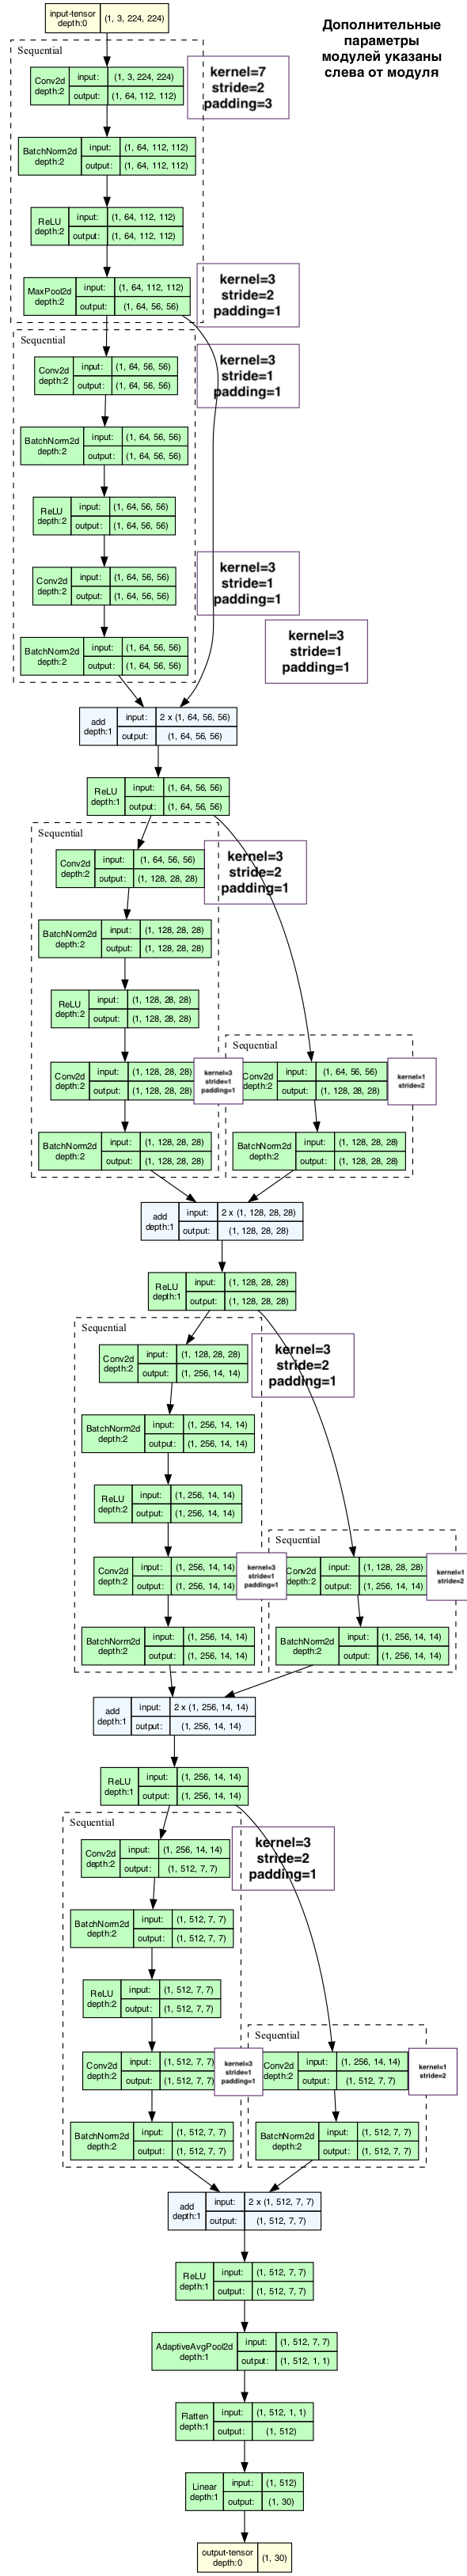

В случае, если по архитектуре выше будет неясно, какие параметры слоев, то еще один скриншот.


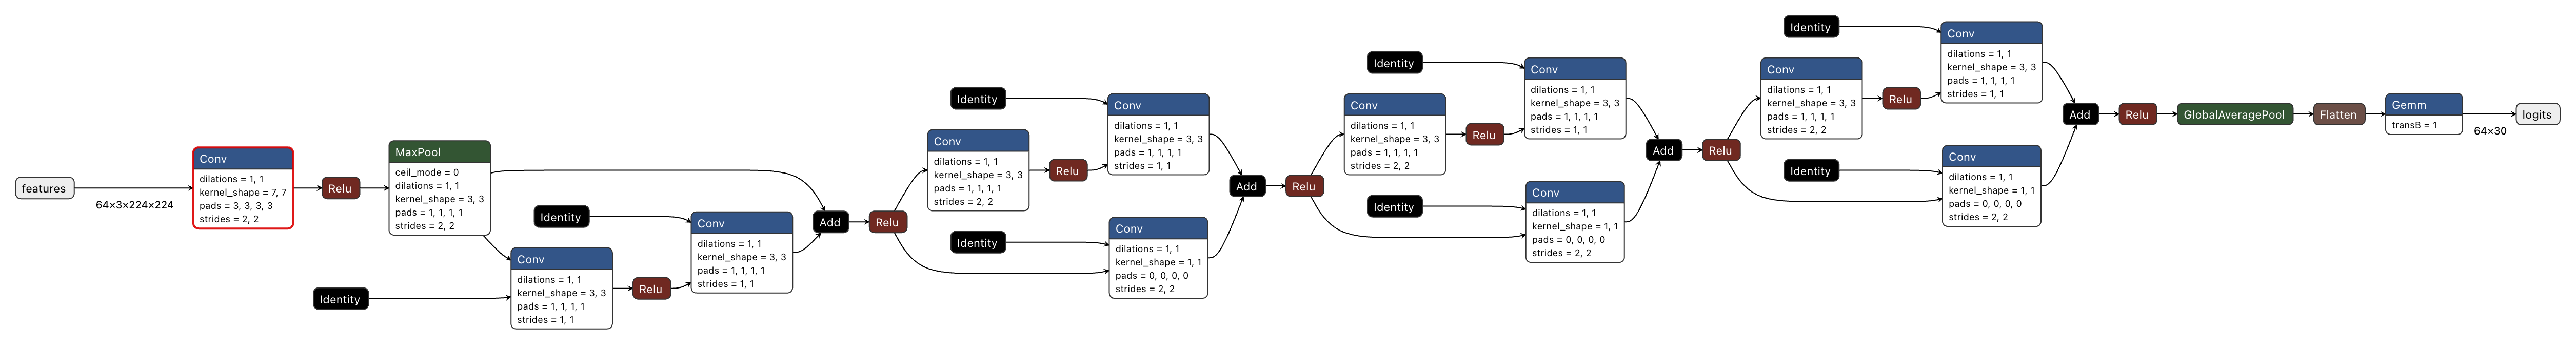

<font color='OrangeRed'>**Обратите внимание!**</font> Все сверточные слои обучаются с параметром `bias=False` (именно в таком варианте обычно применяют свертку, смещение зануляют)

Для блока `GlobalAveragePooling` используйте модуль `nn.AdaptiveAvgPool2d((1, 1))`

In [105]:
import torch.nn.functional as F
from torch import nn

class ResidualBlock(nn.Module):
    def __init__(self, in_channels, out_channels, stride=1, downsample=None):
        super(ResidualBlock, self).__init__()
        self.conv1 = nn.Conv2d(in_channels, out_channels, kernel_size=3, stride=stride, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(out_channels)
        self.relu = nn.ReLU(inplace=True)
        self.conv2 = nn.Conv2d(out_channels, out_channels, kernel_size=3, stride=1, padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(out_channels)
        self.downsample = downsample

    def forward(self, x):
        identity = x

        out = self.conv1(x)
        out = self.bn1(out)
        out = self.relu(out)

        out = self.conv2(out)
        out = self.bn2(out)

        if self.downsample is not None:
            identity = self.downsample(x)

        out += identity
        out = self.relu(out)

        return out

class ResNet18(nn.Module):
    def __init__(self, num_classes=100):
        super(ResNet18, self).__init__()
        self.in_channels = 64

        self.conv1 = nn.Conv2d(3, 64, kernel_size=7, stride=2, padding=3, bias=False)
        self.bn1 = nn.BatchNorm2d(64)
        self.relu = nn.ReLU(inplace=True)
        self.maxpool = nn.MaxPool2d(kernel_size=3, stride=2, padding=1)

        self.layer1 = self._make_layer(64, 2, stride=1)
        self.layer2 = self._make_layer(128, 2, stride=2)
        self.layer3 = self._make_layer(256, 2, stride=2)
        self.layer4 = self._make_layer(512, 2, stride=2)

        self.avgpool = nn.AdaptiveAvgPool2d((1, 1))
        self.fc = nn.Linear(512, num_classes)

    def _make_layer(self, out_channels, blocks, stride=1):
        downsample = None
        if stride != 1 or self.in_channels != out_channels:
            downsample = nn.Sequential(
                nn.Conv2d(self.in_channels, out_channels, kernel_size=1, stride=stride, bias=False),
                nn.BatchNorm2d(out_channels),
            )

        layers = []
        layers.append(ResidualBlock(self.in_channels, out_channels, stride, downsample))
        self.in_channels = out_channels
        for _ in range(1, blocks):
            layers.append(ResidualBlock(self.in_channels, out_channels))

        return nn.Sequential(*layers)

    def forward(self, x):
        x = self.conv1(x)
        x = self.bn1(x)
        x = self.relu(x)
        x = self.maxpool(x)

        x = self.layer1(x)
        x = self.layer2(x)
        x = self.layer3(x)
        x = self.layer4(x)

        x = self.avgpool(x)
        x = torch.flatten(x, 1)
        x = self.fc(x)

        return x


## <font color='DarkOrange'> **Задание 4 [2 баллa]** </font>


Запустите процесс обучения и получите качество не менее 0.8 `Accuracy`

<font color='OrangeRed'>**Внимание!**</font> Перед запуском обучения на GPU убедитесь, что ваш код отрабатывает хотя бы несколько эпох на CPU. Только затем переходите на GPU!

<font color='OrangeRed'>**Внимание!**</font> Обучение уже может быть не мгновенным, поэтому при желании можете добавить в код обучения периодическое сохранение обученной модели. Модифицируйте код по мере обучения, если появляются инсайты

In [106]:
from torch.optim import AdamW
from torch.optim.lr_scheduler import CosineAnnealingLR
from torch import nn

# Увеличиваем n_epoch до 20 для гарантированного достижения Accuracy > 0.8
n_epoch = 20
model = ResNet18(num_classes=30).cuda()
loss_fn = nn.CrossEntropyLoss()
optimizer = AdamW(model.parameters(), lr=1e-3, weight_decay=1e-3)

# Используем косинусное затухание на 20 эпох
scheduler = CosineAnnealingLR(optimizer, T_max=n_epoch * len(dataloader_train), eta_min=1e-6)

In [107]:
def save_checkpoint(epoch, model, optimizer, loss, path="checkpoint.pth"):
    torch.save({
        'epoch': epoch,
        'model_state_dict': model.state_dict(),
        'optimizer_state_dict': optimizer.state_dict(),
        'loss': loss,
    }, path)

def load_checkpoint(path="checkpoint.pth", model=None, optimizer=None):
    checkpoint = torch.load(path)

    if model:
        model.load_state_dict(checkpoint['model_state_dict'])
    if optimizer:
        optimizer.load_state_dict(checkpoint['optimizer_state_dict'])

    epoch = checkpoint['epoch']
    loss = checkpoint['loss']

    return model, optimizer, epoch, loss

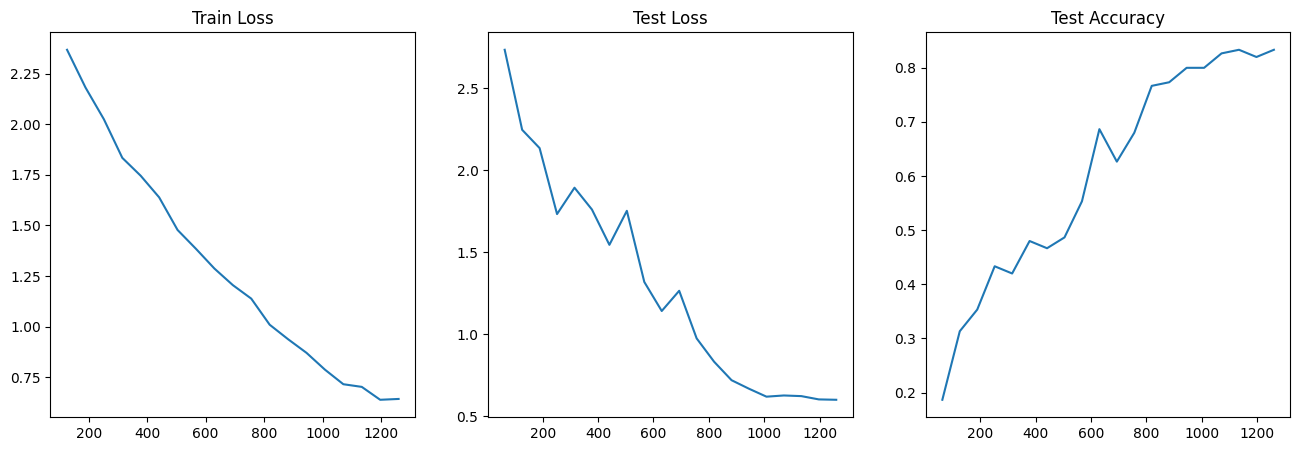

ResNet18(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): ResidualBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    )
    (1): ResidualBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=

In [108]:
iter_list = []
train_loss_list = []
test_loss_list = []
test_accuracy_list = []

global_iter = 0
best_accuracy = 0.0

for epoch in range(n_epoch):
    model.train()
    epoch_loss = 0.0

    for X, target in tqdm(dataloader_train, desc=f'Epoch {epoch + 1}/{n_epoch}'):
        X = X.cuda()
        target = target.cuda()

        optimizer.zero_grad()
        logits = model(X)
        loss = loss_fn(logits, target)
        loss.backward()
        optimizer.step()
        scheduler.step()

        global_iter += 1
        epoch_loss += loss.item()

    # Оценка модели в конце каждой эпохи
    model.eval()
    accuracy, test_loss, _, _ = calc_accuracy(model, dataloader_test)
    iter_list.append(global_iter)
    train_loss_list.append(epoch_loss / len(dataloader_train))
    test_loss_list.append(test_loss)
    test_accuracy_list.append(accuracy.item())
    show_loss(iter_list, train_loss_list, test_loss_list, test_accuracy_list)

    # Сохраняем только наилучшие веса (Best Checkpoint)
    if accuracy.item() > best_accuracy:
        best_accuracy = accuracy.item()
        save_checkpoint(epoch, model, optimizer, epoch_loss / len(dataloader_train))
        print(f"-> Saved new best model checkpoint with accuracy: {best_accuracy:.4f}")

model.eval()

In [109]:
try:
    model, _, _, _ = load_checkpoint("checkpoint.pth", model=model)
    print("Loaded the best saved model checkpoint!")
except Exception as e:
    print("Could not load checkpoint, evaluating current weights:", e)

accuracy, _, y_pred, y_test = calc_accuracy(model, dataloader_test)
print(f"Current Accuracy: {accuracy.item():.4f}")

assert accuracy.item() > 0.8, f"Accuracy is {accuracy.item():.4f}, which is still <= 0.8."
print('Отлично!')

Loaded the best saved model checkpoint!
Current Accuracy: 0.8333
Отлично!
